### Langkah 1 — Persiapan lingkungan dan impor pustaka

In [ ]:
import io, base64, re, os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_colwidth', 80)
print('Pustaka berhasil dimuat.')

Pustaka berhasil dimuat.


### Langkah 2 — Memuat data mahasiswa (tersedia otomatis)

In [ ]:
# Data Excel dilampirkan sebagai Base64 agar notebook mandiri saat dijalankan di Colab.
# Ubah menjadi True hanya bila ingin memilih data Excel baru melalui dialog unggah.
GUNAKAN_UPLOAD_MANUAL = False

DATA_EXCEL_BASE64 = (
    '...'
    'AAAMAAwAHwMAADg2AAAAAA=='
)

if GUNAKAN_UPLOAD_MANUAL:
    from google.colab import files
    unggahan = files.upload()
    nama_file = next(iter(unggahan))
    df = pd.read_excel(io.BytesIO(unggahan[nama_file]))
else:
    nama_file = 'Blank Quiz (Responses 3 TIC).xlsx [data tertanam]'
    df = pd.read_excel(io.BytesIO(base64.b64decode(DATA_EXCEL_BASE64)))

print('Sumber data :', nama_file)
print('Banyak baris:', len(df))
print('Banyak kolom:', len(df.columns))
display(df.iloc[:3, :8])

Sumber data : Blank Quiz (Responses 3 TIC).xlsx [data tertanam]
Banyak baris: 40
Banyak kolom: 35


,Timestamp,Kelas,Jenis Kelamin,Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek (isi dengan num/angka),Jumlah Platform AI yang berlangganan premium atau tidak free (isi dengan num/angka),Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek]
0,2026-11-10 17:30:57.901,3 TI C,Laki-laki,5,2,Sangat Setuju (SS),Sangat Setuju (SS),Setuju (S)
1,2026-11-10 17:31:17.912,3 TI C,Laki-laki,4,2,Setuju (S),Setuju (S),Setuju (S)
2,2026-11-10 17:32:29.676,3 TI C,Laki-laki,3,1,Sangat Setuju (SS),Sangat Setuju (SS),Setuju (S)


### Langkah 3 — Memisahkan metadata dan kandidat butir Likert

In [ ]:
JUMLAH_KOLOM_DEMOGRAFI = 5
metadata = df.iloc[:, :JUMLAH_KOLOM_DEMOGRAFI].copy()
kandidat = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:].copy()
print('Jumlah responden        :', len(df))
print('Kolom pertama/metadata  :', metadata.shape[1])
print('Kolom setelah metadata  :', kandidat.shape[1])
print('Sel kosong setelah metadata:', int(kandidat.isna().sum().sum()))

Jumlah responden        : 40
Kolom pertama/metadata  : 5
Kolom setelah metadata  : 30
Sel kosong setelah metadata: 0


### Langkah 4 — Transformasi jawaban menjadi skor 1–5 dan kontrol kualitas

In [ ]:
skala = {
    'Sangat Tidak Setuju (STS)': 1,
    'Sangat Tidak Setuju (STJ)': 1, # variasi label nyata pada data 3 TI C
    'Tidak Setuju (TS)': 2,
    'Netral (N)': 3,
    'Setuju (S)': 4,
    'Sangat Setuju (SS)': 5,
}

kolom_butir, kolom_dikecualikan = [], []
for kol in kandidat.columns:
    respons = kandidat[kol].astype('string').str.strip()
    is_likert = respons.notna().all() and respons.isin(skala).all()
    is_dimensioned = re.match(r'^\s*(.*?)\s*\[', str(kol)) is not None
    if is_likert and is_dimensioned:
        kolom_butir.append(kol)
    else:
        kolom_dikecualikan.append(kol)

butir = kandidat[kolom_butir].copy()
num = butir.apply(lambda col: col.astype('string').str.strip().map(skala)).astype(float)
print('Jumlah butir Likert:', len(kolom_butir))
print('Kolom non-Likert yang dikecualikan:', len(kolom_dikecualikan))
for c in kolom_dikecualikan:
    print('  -', c, '| jawaban:', kandidat[c].value_counts().to_dict())
print('Sel gagal dikonversi:', int(num.isna().sum().sum()))
print('Frekuensi label STJ:', int((butir == 'Sangat Tidak Setuju (STJ)').sum().sum()))
assert num.isna().sum().sum() == 0, 'Masih ada jawaban Likert yang tidak terbaca.'
assert len(num) >= 3, 'Minimal tiga responden diperlukan.'
display(num.head())

Jumlah butir Likert: 29
Kolom non-Likert yang dikecualikan: 1
  - Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan  | jawaban: {'7 - 10 jam': 20, '4 - 7 jam': 15, '> 10 jam': 5}
Sel gagal dikonversi: 0
Frekuensi label STJ: 51


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya lebih sering menggunakan pemikiran atau jawaban yang dihasilkan AI daripada mengembangkan pemikiran sendiri.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa cemas ketika tidak dapat mengakses AI saat sedang mengerjakan tugas kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Penggunaan AI membuat saya lebih tertarik untuk mempelajari materi perkuliahan.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.],"Kebiasaan penggunaan teknologi digital [Saya sering mengerjakan tugas kuliah sambil melakukan aktivitas lain, seperti membuka media sosial atau menonton video]",Kebiasaan penggunaan teknologi digital [Saya sering memeriksa notifikasi smartphone meskipun sedang mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [Saya sering menunda pengerjaan tugas karena lebih tertarik menggunakan gadget untuk kegiatan lain yang tidak berhubungan dengan tugas yang sedang saya kerjakan],"Kebiasaan penggunaan teknologi digital [Saya merasa menggunakan AI tidak membutuhkan tingkat konsentrasi yang tinggi, sehingga dapat dikerjakan bersamaan dengan kegiatan yang lain.]",Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberikan AI],Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan

### Langkah 5 — Mengelompokkan butir per dimensi

In [ ]:
dimensi = {}
for kolom in butir.columns:
    m = re.match(r'^\s*(.*?)\s*\[', str(kolom))
    if not m:
        raise ValueError(f'Judul kolom tidak sesuai: {kolom}')
    nama = m.group(1).strip().rstrip('.').strip()
    dimensi.setdefault(nama, []).append(kolom)

kode_dimensi = {nama: f'D{i}' for i, nama in enumerate(dimensi, 1)}
for nama, daftar in dimensi.items():
    print(f'{kode_dimensi[nama]} | {nama}: {len(daftar)} butir')
assert sum(len(x) for x in dimensi.values()) == num.shape[1]

D1 | Penggunaan AI pada tugas atau projek kuliah: 7 butir
D2 | Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
D3 | Kebiasaan penggunaan teknologi digital: 6 butir
D4 | Prokrastinasi akademik: 4 butir
D5 | Respon emosional: 5 butir


### Langkah 6 — Uji validitas Pearson item–total

In [ ]:
n = len(num)
alpha_signifikansi = 0.05
def r_kritis(n):
    t = stats.t.ppf(1 - alpha_signifikansi / 2, n - 2)
    return t / np.sqrt((n - 2) + t**2)

r_tabel = r_kritis(n)
print(f'n = {n}; df = {n-2}; r tabel (dua sisi, alpha=0,05) = {r_tabel:.6f}')

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kol in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kol], total)
        r_koreksi, _ = stats.pearsonr(x[kol], total - x[kol])
        hasil_validitas.append({
            'Dimensi': nama,
            'Kode': f'{kode_dimensi[nama]}.B{i}',
            'Butir': f'B{i}',
            'Pernyataan': str(kol).split('[', 1)[-1].rsplit(']', 1)[0],
            'r hitung': float(r),
            'Corrected r': float(r_koreksi),
            'p-value': float(p),
            'r tabel': float(r_tabel),
            'Keterangan': 'Valid' if r > r_tabel else 'Tidak valid',
            'Corrected ≥ 0,30': 'Ya' if r_koreksi >= 0.30 else 'Tidak',
        })
tabel_validitas = pd.DataFrame(hasil_validitas)
display(tabel_validitas[['Kode','r hitung','Corrected r','p-value','r tabel','Keterangan','Corrected ≥ 0,30']].round(4))
print('Valid (r hitung)       :', int((tabel_validitas['Keterangan']=='Valid').sum()))
print('Tidak valid           :', int((tabel_validitas['Keterangan']=='Tidak valid').sum()))
print('Corrected r ≥ 0,30   :', int((tabel_validitas['Corrected r']>=.30).sum()))

n = 40; df = 38; r tabel (dua sisi, alpha=0,05) = 0.312006


,Kode,r hitung,Corrected r,p-value,r tabel,Keterangan,"Corrected ≥ 0,30"
0,D1.B1,0.4193,0.2222,0.0071,0.312,Valid,Tidak
1,D1.B2,0.3899,0.2242,0.0129,0.312,Valid,Tidak
2,D1.B3,0.6263,0.4184,0.0000,0.312,Valid,Ya
3,D1.B4,0.5064,0.2052,0.0009,0.312,Valid,Tidak
4,D1.B5,0.7930,0.5969,0.0000,0.312,Valid,Ya
5,D1.B6,0.6341,0.4236,0.0000,0.312,Valid,Ya
6,D1.B7,0.2313,-0.0606,0.1510,0.312,Tidak valid,Tidak
7,D2.B1,0.5780,0.4366,0.0001,0.312,Valid,Ya
8,D2.B2,0.7078,0.5409,0.0000,0.312,Valid,Ya
9,D2.B3,0.8041,0.6513,0.0000,0.312,Valid,Ya


Valid (r hitung)       : 27
Tidak valid           : 2
Corrected r ≥ 0,30   : 21


### Langkah 7 — Uji reliabilitas Cronbach’s Alpha

In [ ]:
def cronbach_alpha(x):
    # Sama seperti rumus modul: [k / (k-1)] * (1 - sum varians butir / varians skor total)
    x = pd.DataFrame(x)
    k = x.shape[1]
    if k < 2:
        return np.nan
    varians_total = x.sum(axis=1).var(ddof=1)
    if varians_total == 0:
        return np.nan
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / varians_total)

def kategori(a):
    return ('Sangat baik' if a >= 0.90 else 'Baik' if a >= 0.80
            else 'Reliabel' if a >= 0.70 else 'Tidak reliabel')

hasil_reliabilitas, alpha_dihapus = [], []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        'Dimensi': nama, 'Kode': kode_dimensi[nama],
        'Jumlah butir': len(daftar), "Cronbach's alpha": float(a),
        'Kategori': kategori(a)
    })
    if len(daftar) > 2:
        for i, kol in enumerate(daftar, 1):
            alpha_dihapus.append({
                'Dimensi': nama, 'Butir': f'B{i}',
                'Alpha jika dihapus': float(cronbach_alpha(x.drop(columns=kol)))
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=['Dimensi','Butir'], how='left')
display(tabel_reliabilitas.round(4))
display(tabel_alpha_dihapus.round(4))

,Dimensi,Kode,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,D1,7,0.5505,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,D2,7,0.6780,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,D3,6,0.8081,Baik
3,Prokrastinasi akademik,D4,4,0.8650,Baik
4,Respon emosional,D5,5,0.5553,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.5314
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.5328
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.4560
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.5474
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.3411
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.4525
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.6394
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,0.6374
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,0.5969
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,0.5500


### Visualisasi reliabilitas instrumen

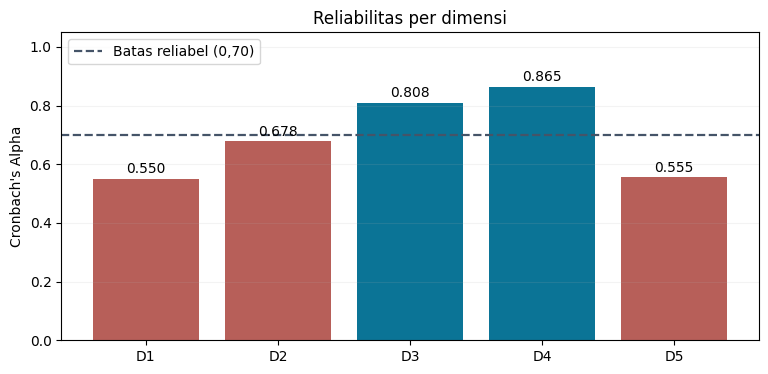

Kode dimensi: {'Penggunaan AI pada tugas atau projek kuliah': 'D1', 'Aspek Psikologis penggunaan AI pada tugas atau projek kuliah': 'D2', 'Kebiasaan penggunaan teknologi digital': 'D3', 'Prokrastinasi akademik': 'D4', 'Respon emosional': 'D5'}


In [ ]:
labels = tabel_reliabilitas['Kode'].tolist()
alpha_vals = tabel_reliabilitas["Cronbach's alpha"].values
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, alpha_vals, color=['#0B7496' if a >= .70 else '#B75F59' for a in alpha_vals])
ax.axhline(.70, linestyle='--', linewidth=1.6, color='#455468', label='Batas reliabel (0,70)')
ax.set_ylim(0,1.05); ax.set_ylabel("Cronbach's Alpha"); ax.set_title('Reliabilitas per dimensi')
for i,v in enumerate(alpha_vals): ax.text(i,v+.02,f'{v:.3f}',ha='center',fontsize=10)
ax.legend(loc='upper left'); ax.grid(axis='y', alpha=.14)
plt.show()
print('Kode dimensi:',kode_dimensi)

## Bagian latihan dan tugas pada modul

Semua lima latihan pada halaman 6 dikerjakan di bawah ini berdasarkan data yang sama. Hasil revisi/penghapusan butir adalah **simulasi statistik**, bukan keputusan final untuk mengubah instrumen tanpa penilaian validitas isi.

### Latihan 1 — Interpretasi butir yang tidak valid

In [ ]:
tidak_valid = gabung[gabung['Keterangan']=='Tidak valid'].copy()
print('r tabel =', round(r_tabel,3))
display(tidak_valid[['Kode','Pernyataan','r hitung','Corrected r','Alpha jika dihapus']].round(4))
print('Interpretasi: butir dengan r hitung ≤ r tabel tidak memenuhi kriteria validitas pada modul.')
print('Dugaan yang perlu ditinjau: ketidaksesuaian arah isi, perbedaan konstruk, atau redaksi ambigu.')

r tabel = 0.312


,Kode,Pernyataan,r hitung,Corrected r,Alpha jika dihapus
6,D1.B7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggun...,0.2313,-0.0606,0.6394
13,D2.B7,Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah m...,-0.0944,-0.2716,0.7694


Interpretasi: butir dengan r hitung ≤ r tabel tidak memenuhi kriteria validitas pada modul.
Dugaan yang perlu ditinjau: ketidaksesuaian arah isi, perbedaan konstruk, atau redaksi ambigu.


### Latihan 2 — Perbandingan r hitung vs corrected r ≥ 0,30

In [ ]:
jumlah_valid = int((gabung['Keterangan']=='Valid').sum())
jumlah_corrected = int((gabung['Corrected r']>=.30).sum())
selisih = jumlah_valid - jumlah_corrected
print(f'Valid menurut r hitung > r tabel  : {jumlah_valid} dari {len(gabung)}')
print(f'Memenuhi corrected r ≥ 0,30      : {jumlah_corrected} dari {len(gabung)}')
print(f'Selisih                           : {selisih} butir')
display(gabung[(gabung['Keterangan']=='Valid')&(gabung['Corrected r']<.30)][['Kode','r hitung','Corrected r']].round(3))
print('Selisih muncul karena corrected item-total mengeluarkan butir dari skor total.')

Valid menurut r hitung > r tabel  : 27 dari 29
Memenuhi corrected r ≥ 0,30      : 21 dari 29
Selisih                           : 6 butir


,Kode,r hitung,Corrected r
0,D1.B1,0.419,0.222
1,D1.B2,0.390,0.224
3,D1.B4,0.506,0.205
12,D2.B6,0.389,0.208
25,D5.B2,0.590,0.297
27,D5.B4,0.413,0.065


Selisih muncul karena corrected item-total mengeluarkan butir dari skor total.


### Latihan 3 — Buang satu butir tidak valid, kemudian uji ulang

In [ ]:
# Pilih butir yang tidak valid dengan kenaikan alpha terbesar jika dihapus.
kandidat_hapus = tidak_valid.copy()
alpha_awal_map = dict(zip(tabel_reliabilitas['Dimensi'], tabel_reliabilitas["Cronbach's alpha"]))
kandidat_hapus['Kenaikan alpha'] = kandidat_hapus.apply(
    lambda r: r['Alpha jika dihapus'] - alpha_awal_map[r['Dimensi']], axis=1)
terpilih = kandidat_hapus.sort_values('Kenaikan alpha',ascending=False).iloc[0]
nama_dim = terpilih['Dimensi']
kolom_hapus = dimensi[nama_dim][int(terpilih['Butir'][1:])-1]
sebelum = num[dimensi[nama_dim]]
sesudah = sebelum.drop(columns=[kolom_hapus])
alpha_sebelum = cronbach_alpha(sebelum)
alpha_sesudah = cronbach_alpha(sesudah)
print('Simulasi menghapus:',terpilih['Kode'],'-',terpilih['Pernyataan'])
print(f'Alpha awal: {alpha_sebelum:.6f}; alpha setelah penghapusan: {alpha_sesudah:.6f}')
print('Status setelah penghapusan:', kategori(alpha_sesudah))
ulang=[]
for col in sesudah.columns:
    rr,pp=stats.pearsonr(sesudah[col],sesudah.sum(axis=1))
    ulang.append({'Butir': f'B{dimensi[nama_dim].index(col)+1}', 'r hitung baru':rr,
                  'p-value':pp, 'Keputusan':'Valid' if rr>r_tabel else 'Tidak valid'})
display(pd.DataFrame(ulang).round(4))
print('Catatan: bila butir merupakan pernyataan positif pada skala yang dominan negatif,')
print('pertimbangkan uji reverse coding setelah memastikan arah konstruk secara teoretis.')

Simulasi menghapus: D2.B7 - Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.
Alpha awal: 0.678043; alpha setelah penghapusan: 0.769390
Status setelah penghapusan: Reliabel


,Butir,r hitung baru,p-value,Keputusan
0,B1,0.6069,0.0000,Valid
1,B2,0.7389,0.0000,Valid
2,B3,0.7904,0.0000,Valid
3,B4,0.6568,0.0000,Valid
4,B5,0.8192,0.0000,Valid
5,B6,0.4206,0.0069,Valid


Catatan: bila butir merupakan pernyataan positif pada skala yang dominan negatif,
pertimbangkan uji reverse coding setelah memastikan arah konstruk secara teoretis.


### Latihan 4 — Pengaruh pengurangan ukuran sampel (n = 20)

In [ ]:
# Sesuai modul: sample(20, random_state=1)
subset = num.sample(n=20, random_state=1)
r_tabel20=r_kritis(len(subset))
hasil_subset=[]
for nama, cols in dimensi.items():
    z = subset[cols]
    tot = z.sum(axis=1)
    for i,col in enumerate(cols,1):
        rr,_=stats.pearsonr(z[col],tot)
        hasil_subset.append({'Kode':f'{kode_dimensi[nama]}.B{i}', 'r hitung n=20':rr,
                             'Status n=20': 'Valid' if rr>r_tabel20 else 'Tidak valid'})
tabel_subset = pd.DataFrame(hasil_subset)
jumlah_subset = int((tabel_subset['Status n=20']=='Valid').sum())
print(f'Sampel penuh: n={n}, r tabel={r_tabel:.3f}, valid={jumlah_valid}/{len(num.columns)}')
print(f'Sampel acak: n=20, r tabel={r_tabel20:.3f}, valid={jumlah_subset}/{len(num.columns)}')
display(tabel_subset[tabel_subset['Status n=20']=='Tidak valid'].round(4))
print('Saat n berkurang, nilai kritis r membesar dan estimasi korelasi dapat berfluktuasi.')

Sampel penuh: n=40, r tabel=0.312, valid=27/29
Sampel acak: n=20, r tabel=0.444, valid=23/29


,Kode,r hitung n=20,Status n=20
0,D1.B1,0.3687,Tidak valid
1,D1.B2,0.2180,Tidak valid
6,D1.B7,0.3687,Tidak valid
12,D2.B6,0.2883,Tidak valid
13,D2.B7,-0.1514,Tidak valid
27,D5.B4,0.4160,Tidak valid


Saat n berkurang, nilai kritis r membesar dan estimasi korelasi dapat berfluktuasi.


### Latihan 5 — Refleksi

Instrumen dapat **reliabel tetapi tidak valid** karena konsistensi jawaban tidak menjamin ketepatan konstruk. Misalnya, seluruh pertanyaan tentang frekuensi bermain gim dapat saling berkorelasi dan menghasilkan alpha tinggi, tetapi tetap tidak valid apabila tujuan penelitian adalah mengukur **prokrastinasi akademik** tanpa menanyakan perilaku menunda tugas. Reliabilitas merupakan syarat penting, tetapi tidak cukup untuk menyimpulkan validitas.

### Langkah 8 — Ekspor lampiran Excel hasil pengujian

In [ ]:
file_output='hasil_uji_validitas_reliabilitas_3TIC_colab.xlsx'
with pd.ExcelWriter(file_output,engine='openpyxl') as writer:
    gabung.to_excel(writer,sheet_name='Validitas',index=False)
    tabel_reliabilitas.to_excel(writer,sheet_name='Reliabilitas',index=False)
    num.rename(columns={col: f'{kode_dimensi[nama]}.B{i}' for nama,cols in dimensi.items() for i,col in enumerate(cols,1)}).to_excel(
        writer,sheet_name='Data Skor',index=False)
    tabel_subset.to_excel(writer,sheet_name='Latihan Sampel 20',index=False)
    pd.DataFrame(ulang).to_excel(writer,sheet_name='Latihan Hapus Butir',index=False)
print('Berhasil membuat:',file_output)
print('Di Colab: klik panel Files untuk mengunduh, atau jalankan sel opsional berikut:')

Berhasil membuat: hasil_uji_validitas_reliabilitas_3TIC_colab.xlsx
Di Colab: klik panel Files untuk mengunduh, atau jalankan sel opsional berikut:
